# Bước 6: Regression Analysis
## UK Weather & Health: Weekly Deaths and Temperature (2016–2024)

**Mục tiêu**: Dự báo `deaths_total` dựa trên các biến nhiệt độ & lag. Kiểm định ý nghĩa thống kê, đánh giá mô hình, phân tích residual.

---

> **Reproducibility / audit note (2026-11-13).** Run this notebook with the other notebooks and the five included data files in the **same directory**. Start with `Kernel > Restart & Run All`. The observed table has **442 real weeks**; the prepared regular grid has **469 weeks** (27 interpolated rows), and the forecasting table after lag-1 has **468 rows** (374 train / 94 observed test). This project analyzes association and **retrospective** forecasts—not causal effects or an operational heat-health warning. The original report-alignment figures and formulas are retained where they can be reproduced; any additional checks are labeled explicitly.

## 6.1 Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.dpi'] = 100

# Load dataset
df = pd.read_csv('uk_weather_health_weekly_CLEANED.csv',
                  parse_dates=['week_start_sat', 'week_start_mon', 'week_end'])
df = df.sort_values('week_start_mon').reset_index(drop=True)

print(f'Dataset: {df.shape[0]} rows × {df.shape[1]} columns')
df.head(3)

Dataset: 469 rows × 13 columns


,week_start_sat,week_start_mon,week_end,deaths_total,tasmax_mean_weekly_degC,tasmax_max_weekly_degC,year,month,week_of_year,quarter,season,temp_range_weekly,IsSurge
0,2016-01-02,2016-01-04,2016-01-08,13045.0,7.363329,8.839454,2016,1,1,1,Winter,1.476125,1
1,2016-01-09,2016-01-11,2016-01-15,11501.0,5.132909,7.135659,2016,1,2,1,Winter,2.002750,1
2,2016-01-16,2016-01-18,2016-01-22,11473.0,5.359014,10.233992,2016,1,3,1,Winter,4.874978,0


## 6.2 Feature Engineering — Tạo biến đầu vào cho mô hình

In [2]:
# Tạo lag_1_deaths: tử vong tuần trước
df['lag_1_deaths'] = df['deaths_total'].shift(1)

# Tạo month_index (= month) — đã có sẵn trong dataset
# Tạo biến month dummy (One-Hot Encoding)
df = pd.get_dummies(df, columns=['month'], drop_first=True, dtype=int)

# Tạo biến mùa hè
df['is_summer'] = (df['season'] == 'Summer').astype(int)

# Tạo biến tương tác: nhiệt độ × mùa hè (để đo hiệu ứng nhiệt mùa hè)
df['temp_x_summer'] = df['tasmax_mean_weekly_degC'] * df['is_summer']

# Drop hàng đầu tiên (NaN do lag)
df_model = df.dropna(subset=['lag_1_deaths']).copy()

print(f'Dataset sau feature engineering: {df_model.shape[0]} rows')
print(f'\nCác biến mới:')
print(f'  lag_1_deaths: tử vong tuần trước (t-1)')
print(f'  is_summer:    1 nếu mùa hè, 0 nếu không')
print(f'  temp_x_summer: tasmax_mean × is_summer (interaction term)')
print(f'\nThống kê biến mới:')
df_model[['lag_1_deaths', 'is_summer', 'temp_x_summer']].describe().round(2)

Dataset sau feature engineering: 468 rows

Các biến mới:
  lag_1_deaths: tử vong tuần trước (t-1)
  is_summer:    1 nếu mùa hè, 0 nếu không
  temp_x_summer: tasmax_mean × is_summer (interaction term)

Thống kê biến mới:


,lag_1_deaths,is_summer,temp_x_summer
count,468.00,468.00,468.00
mean,10748.38,0.25,4.92
std,1851.99,0.43,8.55
min,6825.00,0.00,0.00
25%,9635.75,0.00,0.00
50%,10471.00,0.00,0.00
75%,11484.50,1.00,14.37
max,22351.00,1.00,25.45


## 6.3 Kiểm tra Đa cộng tuyến (VIF) giữa `tasmax_mean` và `tasmax_max`

In [3]:
# Kiểm tra VIF cho các biến nhiệt độ
month_cols = [c for c in df_model.columns if c.startswith('month_')]
vif_cols = ['tasmax_mean_weekly_degC', 'tasmax_max_weekly_degC', 'lag_1_deaths'] + month_cols
X_vif = df_model[vif_cols].copy()
X_vif = sm.add_constant(X_vif)

vif_data = pd.DataFrame({
    'Biến': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).round(2)

print('KIỂM TRA ĐA CỘNG TUYẾN (VIF):')
print('=' * 50)
print(vif_data.to_string(index=False))
print()

# Tương quan giữa 2 biến nhiệt độ
r_temp, p_temp = stats.pearsonr(df_model['tasmax_mean_weekly_degC'], df_model['tasmax_max_weekly_degC'])
print(f'Pearson r (tasmax_mean vs tasmax_max) = {r_temp:.4f}, p = {p_temp:.2e}')

if vif_data[vif_data['Biến'] == 'tasmax_max_weekly_degC']['VIF'].values[0] > 10:
    print('\n  VIF > 10 → Đa cộng tuyến CAO giữa tasmax_mean & tasmax_max')
    print('→ Quyết định: LOẠI BỎ tasmax_max, chỉ giữ tasmax_mean để tránh multicollinearity')
    drop_tasmax_max = True
else:
    print('\n VIF < 10 → Có thể giữ cả hai biến nhiệt độ')
    drop_tasmax_max = False

KIỂM TRA ĐA CỘNG TUYẾN (VIF):
                   Biến   VIF
                  const 92.51
tasmax_mean_weekly_degC 28.73
 tasmax_max_weekly_degC 20.99
           lag_1_deaths  1.51
                month_2  1.79
                month_3  2.00
                month_4  2.35
                month_5  3.47
                month_6  4.38
                month_7  5.32
                month_8  5.00
                month_9  3.96
               month_10  2.86
               month_11  1.99
               month_12  1.87

Pearson r (tasmax_mean vs tasmax_max) = 0.9743, p = 1.17e-303

  VIF > 10 → Đa cộng tuyến CAO giữa tasmax_mean & tasmax_max
→ Quyết định: LOẠI BỎ tasmax_max, chỉ giữ tasmax_mean để tránh multicollinearity


## 6.4 Mô hình 1: OLS Linear Regression (Baseline)

**Biến đầu vào**: `tasmax_mean`, `month`, `lag_1_deaths`  
**Biến mục tiêu**: `deaths_total`

In [4]:
# Chọn features sau khi loại bỏ đa cộng tuyến
month_cols = [c for c in df_model.columns if c.startswith('month_')]
feature_cols = ['tasmax_mean_weekly_degC', 'lag_1_deaths'] + month_cols
target = 'deaths_total'

X = df_model[feature_cols]
y = df_model[target]

# Train/Test split: 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# OLS với statsmodels (để có p-value, CI, F-test)
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:           deaths_total   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.667
Method:                 Least Squares   F-statistic:                     58.57
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.75e-80
Time:                        15:09:22   Log-Likelihood:                -3159.5
No. Observations:                 374   AIC:                             6347.
Df Residuals:                     360   BIC:                             6402.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                    5

## 6.5 Kiểm định ý nghĩa thống kê — Nhiệt độ có ảnh hưởng đến tử vong?

In [5]:
print('KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ CỦA CÁC BIẾN:')
print('=' * 65)

results_df = pd.DataFrame({
    'Biến': ols_model.params.index,
    'Hệ số (β)': ols_model.params.values,
    'Std Error': ols_model.bse.values,
    't-value': ols_model.tvalues.values,
    'p-value': ols_model.pvalues.values,
    'Significant?': [' Yes' if p < 0.05 else ' No' for p in ols_model.pvalues.values]
}).round(4)

print(results_df.to_string(index=False))

print(f'\n--- Kiểm định tổng thể ---')
print(f'F-statistic = {ols_model.fvalue:.2f}, p(F) = {ols_model.f_pvalue:.2e}')
print(f'R² (train) = {ols_model.rsquared:.4f}')
print(f'Adj R² (train) = {ols_model.rsquared_adj:.4f}')

# Giải thích hệ số nhiệt độ
coef_temp = ols_model.params['tasmax_mean_weekly_degC']
p_temp = ols_model.pvalues['tasmax_mean_weekly_degC']
print(f'\n--- Giải thích hệ số nhiệt độ ---')
print(f'β(tasmax_mean) = {coef_temp:.2f}')
print(f'p-value = {p_temp:.4f}')
if p_temp < 0.05:
    print(f'→ Nhiệt độ CÓ ý nghĩa thống kê (p < 0.05)')
    print(f'→ Khi nhiệt độ tăng 1°C (giữ các biến khác không đổi), tử vong thay đổi {coef_temp:.1f} ca/tuần')
else:
    print(f'→ Nhiệt độ KHÔNG có ý nghĩa thống kê trong mô hình này (p ≥ 0.05)')

KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ CỦA CÁC BIẾN:
                   Biến  Hệ số (β)  Std Error  t-value  p-value Significant?
                  const  5019.7429   541.9592   9.2622   0.0000          Yes
tasmax_mean_weekly_degC    12.2088    28.5123   0.4282   0.6688           No
           lag_1_deaths     0.6552     0.0364  17.9754   0.0000          Yes
                month_2 -1265.9747   280.9054  -4.5068   0.0000          Yes
                month_3 -1477.7667   301.2518  -4.9054   0.0000          Yes
                month_4  -961.6983   327.4267  -2.9371   0.0035          Yes
                month_5 -2292.7501   386.8540  -5.9267   0.0000          Yes
                month_6 -1750.7647   457.7805  -3.8245   0.0002          Yes
                month_7 -2004.2888   496.6899  -4.0353   0.0001          Yes
                month_8 -2264.8378   475.6116  -4.7619   0.0000          Yes
                month_9 -1605.9328   432.1580  -3.7161   0.0002          Yes
               month_10 -1528.1810 

## 6.6 Hiệu ứng nhiệt độ mùa hè — Khi tăng 1°C vào mùa hè, tử vong tăng bao nhiêu?

In [6]:
# Mô hình OLS với interaction term (temp × summer)
month_cols = [c for c in df_model.columns if c.startswith('month_')]
# is_summer is already determined by the month dummies (perfect collinearity).
feature_summer = ['tasmax_mean_weekly_degC', 'lag_1_deaths', 'temp_x_summer'] + month_cols

X_summer = df_model[feature_summer]
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_summer, y, test_size=0.2, shuffle=False)

X_train_s_sm = sm.add_constant(X_train_s)
ols_summer = sm.OLS(y_train_s, X_train_s_sm).fit()

print('MÔ HÌNH VỚI INTERACTION TERM (Nhiệt độ × Mùa hè):')
print('=' * 65)
print(ols_summer.summary2().tables[1].to_string())

coef_temp_base = ols_summer.params['tasmax_mean_weekly_degC']
coef_interaction = ols_summer.params['temp_x_summer']
p_interaction = ols_summer.pvalues['temp_x_summer']

summer_effect = coef_temp_base + coef_interaction

print(f'\n--- Hiệu ứng nhiệt độ theo mùa ---')
print(f'Hiệu ứng nhiệt độ NGOÀI mùa hè: {coef_temp_base:.2f} ca/°C')
print(f'Hiệu ứng thêm trong MÙA HÈ:     {coef_interaction:.2f} ca/°C')
print(f'Tổng hiệu ứng MÙA HÈ:            {summer_effect:.2f} ca/°C')
print(f'p-value (interaction):             {p_interaction:.4f}')
print(f'\n→ Khi nhiệt độ tăng 1°C vào mùa hè, tử vong thay đổi khoảng {summer_effect:.0f} ca/tuần')
if p_interaction < 0.05:
    print('→ Hiệu ứng interaction CÓ ý nghĩa thống kê')
else:
    print('→ Hiệu ứng interaction KHÔNG có ý nghĩa thống kê — chưa đủ bằng chứng hiệu ứng khác biệt theo mùa hè')
print('Các hệ số là association trong dữ liệu quan sát, không xác lập tác động nhân quả.')


MÔ HÌNH VỚI INTERACTION TERM (Nhiệt độ × Mùa hè):
                               Coef.     Std.Err.          t         P>|t|       [0.025       0.975]
const                    5153.939347   555.685813   9.274916  1.700996e-18  4061.130996  6246.747699
tasmax_mean_weekly_degC    -5.905499    33.011994  -0.178890  8.581254e-01   -70.826687    59.015689
lag_1_deaths                0.654607     0.036443  17.962525  6.310832e-52     0.582938     0.726275
temp_x_summer              71.145569    65.398204   1.087883  2.773767e-01   -57.466142   199.757280
month_2                 -1253.891117   281.053367  -4.461399  1.091018e-05 -1806.608965  -701.173270
month_3                 -1431.320049   304.186168  -4.705408  3.621941e-06 -2029.530724  -833.109375
month_4                  -867.766106   338.539372  -2.563265  1.077606e-02 -1533.535583  -201.996628
month_5                 -2136.290102   412.630753  -5.177244  3.758260e-07 -2947.767239 -1324.812965
month_6                 -2862.486735  111

## 6.7 Đánh giá mô hình OLS — $R^2$ và RMSE

ĐÁNH GIÁ MÔ HÌNH OLS LINEAR REGRESSION:
  Metric     Train      Test
      R²    0.6790    0.1695
  Adj R²    0.6674       NaN
    RMSE 1128.9041 1049.0247
     MAE  706.9558  668.4018
MAPE (%)    6.4766    6.6568


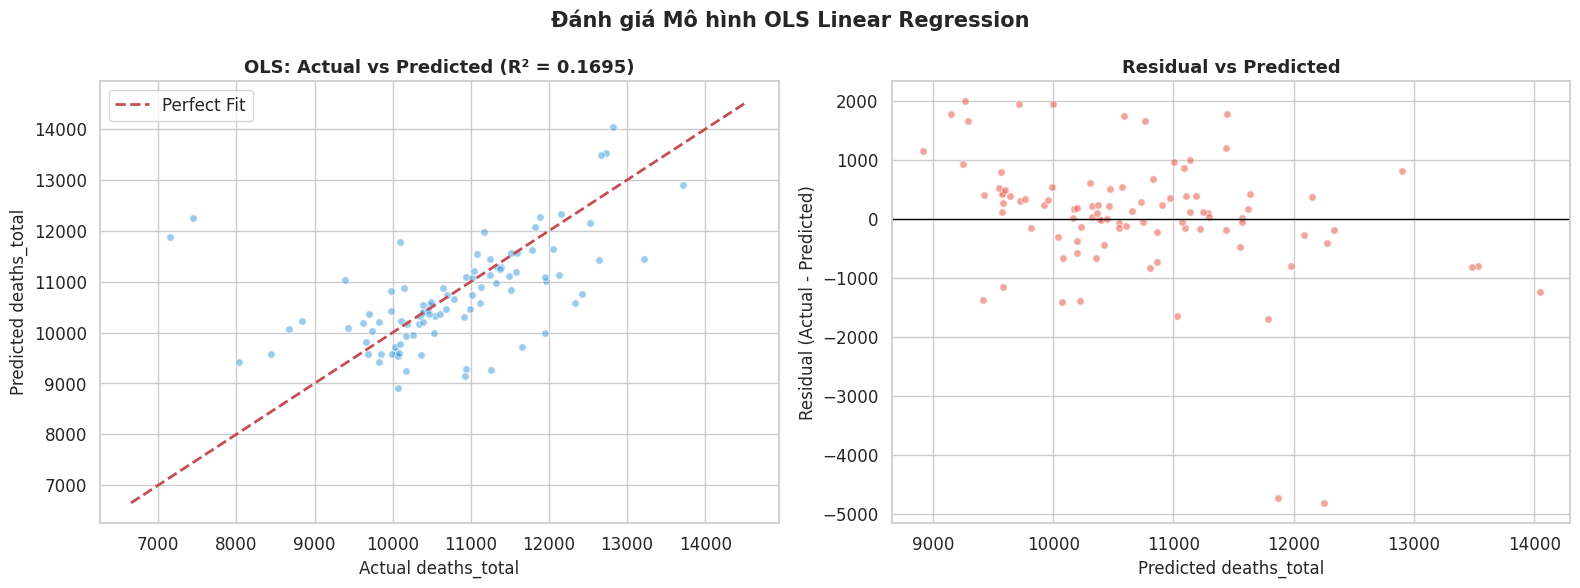

In [7]:
# Dự báo trên test set
y_pred_train = ols_model.predict(X_train_sm)
y_pred_test = ols_model.predict(X_test_sm)

# Metrics
metrics = {
    'Metric': ['R²', 'Adj R²', 'RMSE', 'MAE', 'MAPE (%)'],
    'Train': [
        r2_score(y_train, y_pred_train),
        ols_model.rsquared_adj,
        np.sqrt(mean_squared_error(y_train, y_pred_train)),
        mean_absolute_error(y_train, y_pred_train),
        np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100
    ],
    'Test': [
        r2_score(y_test, y_pred_test),
        np.nan,  # Adj R² chỉ có cho train
        np.sqrt(mean_squared_error(y_test, y_pred_test)),
        mean_absolute_error(y_test, y_pred_test),
        np.mean(np.abs((y_test - y_pred_test) / y_test)) * 100
    ]
}
metrics_df = pd.DataFrame(metrics).round(4)

print('ĐÁNH GIÁ MÔ HÌNH OLS LINEAR REGRESSION:')
print('=' * 50)
print(metrics_df.to_string(index=False))

# Visualize Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter actual vs predicted
axes[0].scatter(y_test, y_pred_test, alpha=0.5, s=30, color='#3498db', edgecolor='white')
min_val = min(y_test.min(), y_pred_test.min()) - 500
max_val = max(y_test.max(), y_pred_test.max()) + 500
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Fit')
axes[0].set_xlabel('Actual deaths_total', fontsize=12)
axes[0].set_ylabel('Predicted deaths_total', fontsize=12)
axes[0].set_title(f'OLS: Actual vs Predicted (R² = {r2_score(y_test, y_pred_test):.4f})',
                   fontweight='bold', fontsize=13)
axes[0].legend()

# Prediction error plot
errors = y_test.values - y_pred_test
axes[1].scatter(y_pred_test, errors, alpha=0.5, s=30, color='#e74c3c', edgecolor='white')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Predicted deaths_total', fontsize=12)
axes[1].set_ylabel('Residual (Actual - Predicted)', fontsize=12)
axes[1].set_title('Residual vs Predicted', fontweight='bold', fontsize=13)

plt.suptitle('Đánh giá Mô hình OLS Linear Regression', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 6.8 Polynomial degree 1, 2 and 3: multivariable design

A higher-order model does **not** alone establish a U-shaped temperature–mortality causal effect.

SO SÁNH LINEAR vs POLYNOMIAL REGRESSION:
 Degree  R² (test)  RMSE (test)  MAE (test)  Num Features
      1     0.1695    1049.0247    668.4018            13
      2     0.3243     946.2378    650.0166           104
      3     0.0920    1096.8983    710.4349           559


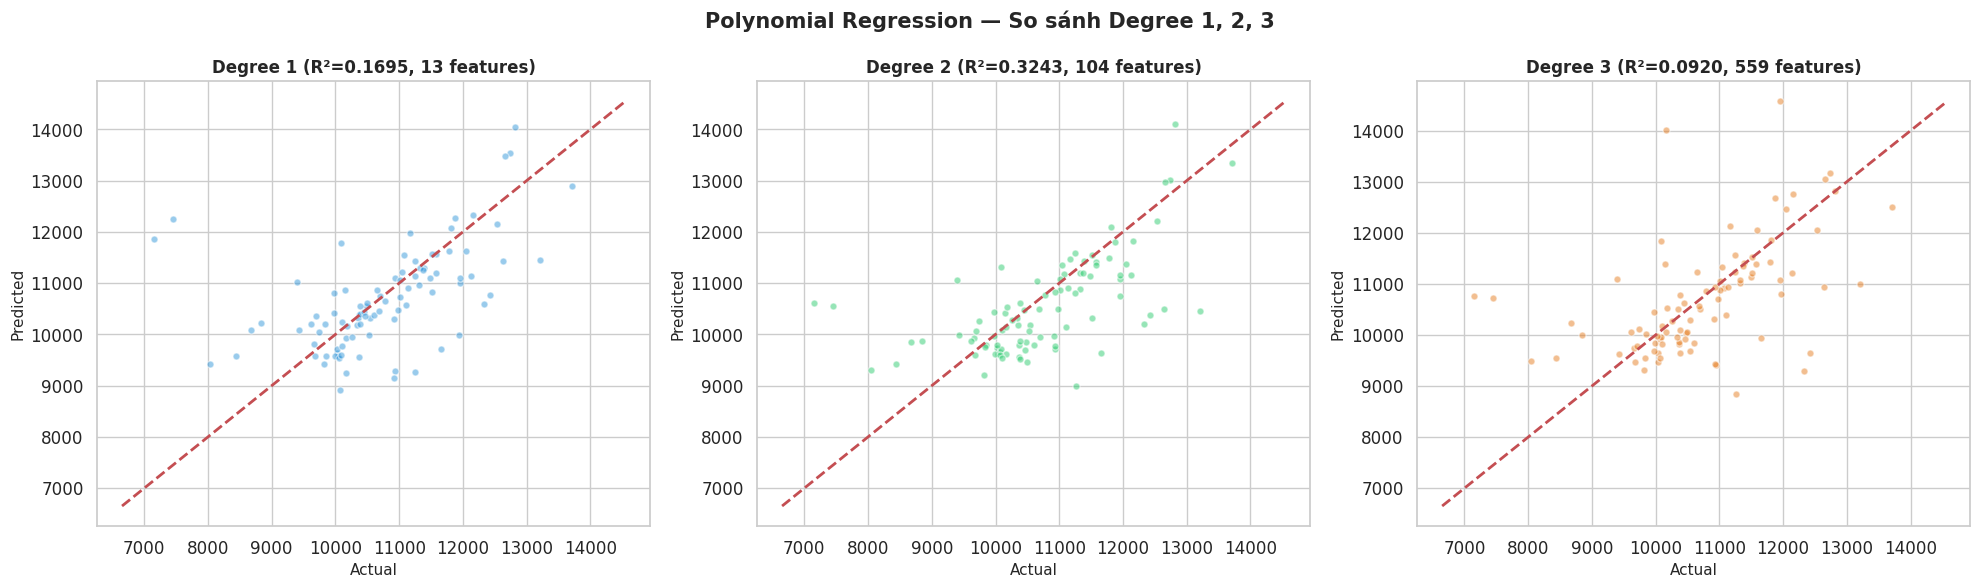


→ Degree 2 cho R² cao nhất = 0.3243
Degree >1 can improve multivariable fit; it does NOT establish a temperature risk U/J curve.


In [8]:
# So sánh Linear vs Polynomial (degree 2, 3)
results_poly = []

for degree in [1, 2, 3]:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression())
    ])
    pipe.fit(X_train, y_train)
    y_pred_p = pipe.predict(X_test)

    results_poly.append({
        'Degree': degree,
        'R² (test)': r2_score(y_test, y_pred_p),
        'RMSE (test)': np.sqrt(mean_squared_error(y_test, y_pred_p)),
        'MAE (test)': mean_absolute_error(y_test, y_pred_p),
        'Num Features': pipe.named_steps['poly'].n_output_features_
    })

poly_df = pd.DataFrame(results_poly).round(4)
print('SO SÁNH LINEAR vs POLYNOMIAL REGRESSION:')
print('=' * 65)
print(poly_df.to_string(index=False))

# Biểu đồ so sánh
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors_deg = ['#3498db', '#2ecc71', '#e67e22']

for idx, degree in enumerate([1, 2, 3]):
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression())
    ])
    pipe.fit(X_train, y_train)
    y_pred_p = pipe.predict(X_test)
    r2 = r2_score(y_test, y_pred_p)

    axes[idx].scatter(y_test, y_pred_p, alpha=0.5, s=25, color=colors_deg[idx], edgecolor='white')
    axes[idx].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
    axes[idx].set_xlabel('Actual', fontsize=11)
    axes[idx].set_ylabel('Predicted', fontsize=11)
    axes[idx].set_title(f'Degree {degree} (R²={r2:.4f}, {results_poly[idx]["Num Features"]} features)',
                         fontweight='bold', fontsize=12)

plt.suptitle('Polynomial Regression — So sánh Degree 1, 2, 3', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

best = poly_df.loc[poly_df['R² (test)'].idxmax()]
print(f'\n→ Degree {int(best["Degree"])} cho R² cao nhất = {best["R² (test)"]:.4f}')
if best['Degree'] > 1:
    print('Degree >1 can improve multivariable fit; it does NOT establish a temperature risk U/J curve.')
else:
    print('→ KHÔNG cần Polynomial: Linear đã đủ tốt')

## 6.9 Residual Analysis — Sai số phân bố ngẫu nhiên?

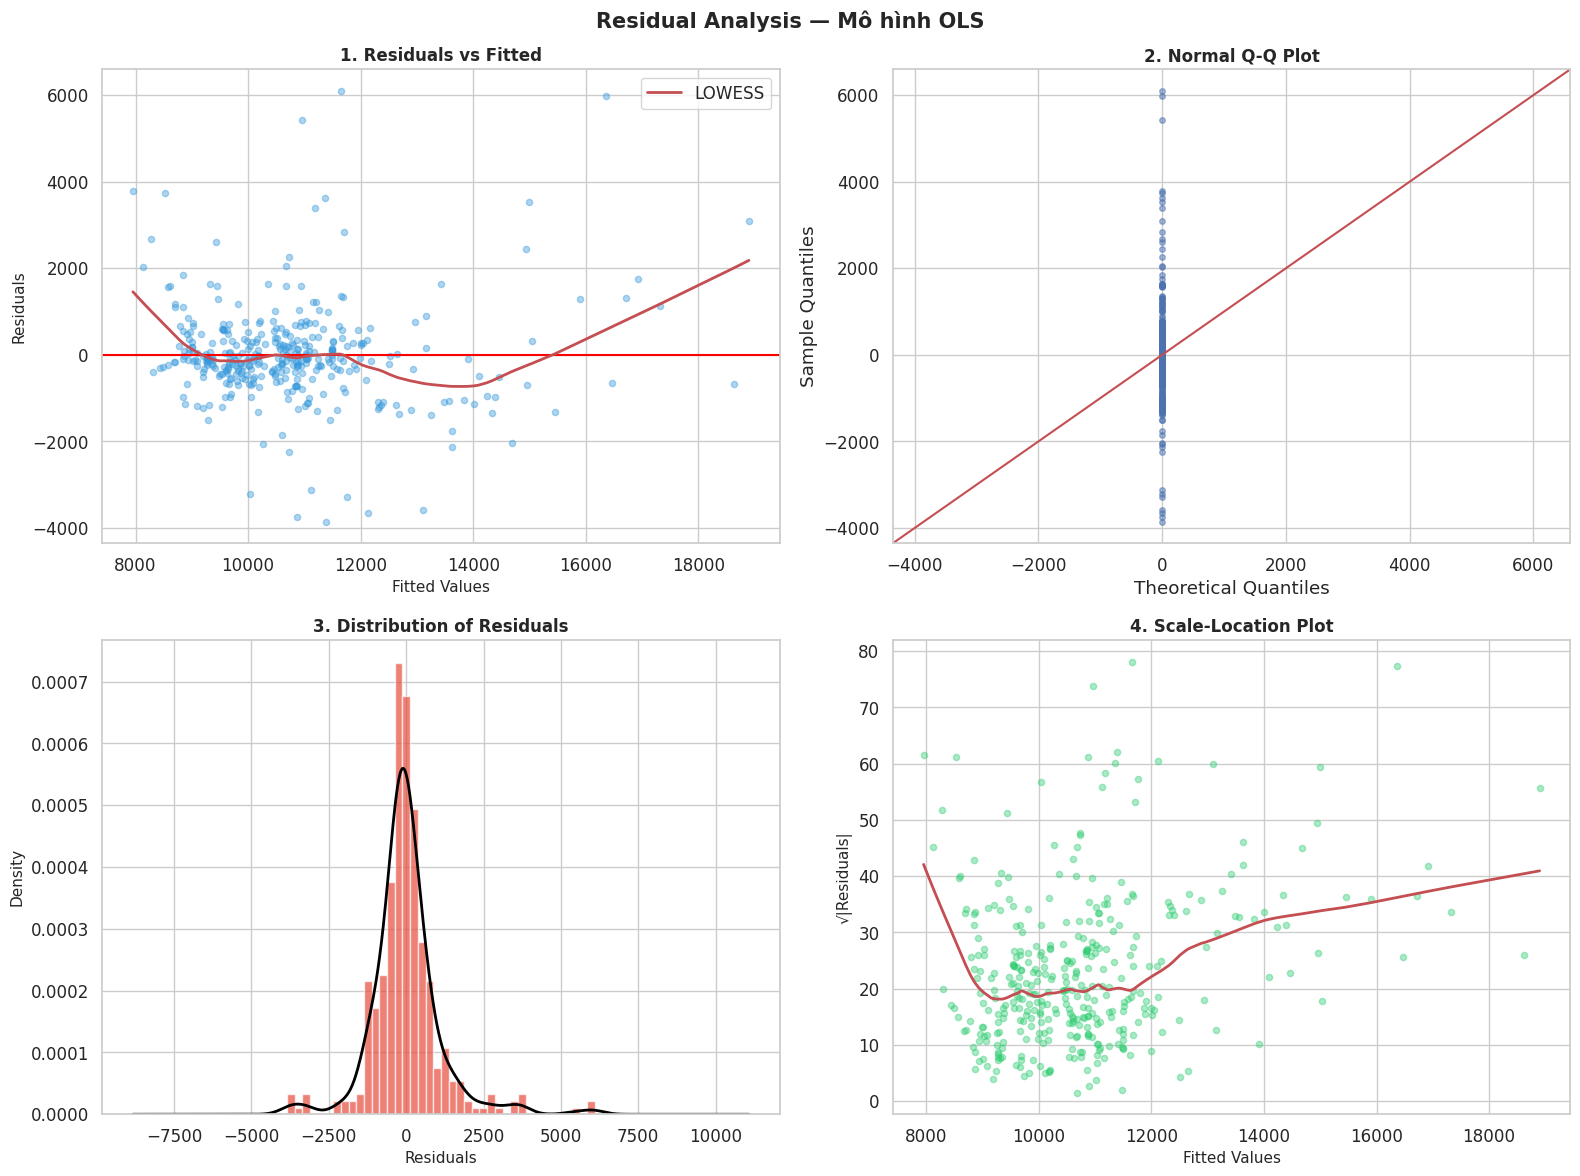

KIỂM ĐỊNH RESIDUALS:
Shapiro-Wilk (normality): W=0.8595, p=0.0000 → Residuals NOT normal
Durbin-Watson (autocorr): DW=2.0153 → No significant autocorrelation 
Breusch-Pagan (heterosc): χ²=46.8979, p=0.0000 → Heteroscedasticity 


In [9]:
# Residuals từ mô hình OLS
residuals_train = ols_model.resid
fitted_train = ols_model.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Residuals vs Fitted
axes[0, 0].scatter(fitted_train, residuals_train, alpha=0.4, s=20, color='#3498db')
axes[0, 0].axhline(0, color='red', linewidth=1.5)
axes[0, 0].set_xlabel('Fitted Values', fontsize=11)
axes[0, 0].set_ylabel('Residuals', fontsize=11)
axes[0, 0].set_title('1. Residuals vs Fitted', fontweight='bold', fontsize=12)

# Thêm lowess smoothing
lowess = sm.nonparametric.lowess(residuals_train, fitted_train, frac=0.3)
axes[0, 0].plot(lowess[:, 0], lowess[:, 1], 'r-', linewidth=2, label='LOWESS')
axes[0, 0].legend()

# 2. QQ-Plot
sm.qqplot(residuals_train, line='45', ax=axes[0, 1], markersize=4, alpha=0.5)
axes[0, 1].set_title('2. Normal Q-Q Plot', fontweight='bold', fontsize=12)

# 3. Histogram of Residuals
axes[1, 0].hist(residuals_train, bins=40, color='#e74c3c', edgecolor='white', alpha=0.7, density=True)
residuals_train.plot.kde(ax=axes[1, 0], color='black', linewidth=2)
axes[1, 0].set_xlabel('Residuals', fontsize=11)
axes[1, 0].set_ylabel('Density', fontsize=11)
axes[1, 0].set_title('3. Distribution of Residuals', fontweight='bold', fontsize=12)

# 4. Scale-Location (sqrt(|residuals|) vs fitted)
sqrt_resid = np.sqrt(np.abs(residuals_train))
axes[1, 1].scatter(fitted_train, sqrt_resid, alpha=0.4, s=20, color='#2ecc71')
lowess2 = sm.nonparametric.lowess(sqrt_resid, fitted_train, frac=0.3)
axes[1, 1].plot(lowess2[:, 0], lowess2[:, 1], 'r-', linewidth=2)
axes[1, 1].set_xlabel('Fitted Values', fontsize=11)
axes[1, 1].set_ylabel('√|Residuals|', fontsize=11)
axes[1, 1].set_title('4. Scale-Location Plot', fontweight='bold', fontsize=12)

plt.suptitle('Residual Analysis — Mô hình OLS', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Kiểm định thống kê
print('KIỂM ĐỊNH RESIDUALS:')
print('=' * 55)

# Shapiro-Wilk test (normality)
stat_sw, p_sw = stats.shapiro(residuals_train[:500])  # max 5000 samples
print(f'Shapiro-Wilk (normality): W={stat_sw:.4f}, p={p_sw:.4f}', end='')
print(' → Residuals NOT normal' if p_sw < 0.05 else ' → Residuals ~normal')

# Durbin-Watson (autocorrelation)
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(residuals_train)
print(f'Durbin-Watson (autocorr): DW={dw:.4f}', end='')
if dw < 1.5:
    print(' → Positive autocorrelation ')
elif dw > 2.5:
    print(' → Negative autocorrelation ')
else:
    print(' → No significant autocorrelation ')

# Breusch-Pagan test (heteroscedasticity)
bp_stat, bp_p, _, _ = het_breuschpagan(residuals_train, X_train_sm)
print(f'Breusch-Pagan (heterosc): χ²={bp_stat:.4f}, p={bp_p:.4f}', end='')
print(' → Heteroscedasticity ' if bp_p < 0.05 else ' → Homoscedasticity ')

## 6.10 Regularization — Ridge & Lasso để tránh Overfitting

> **Audit:** `reg_df` originally compares alpha values using test R². This is now labeled **exploratory only**. The final §6.11 Ridge/Lasso model choices use training-only `TimeSeriesSplit`. Separate §6.13 reproduces fixed-alpha figures from the published paper; those use the original reused test block and are not an independently tuned result.


SO SÁNH OLS vs RIDGE vs LASSO:
         Model Alpha  R² Train  R² Test  RMSE Test
OLS (baseline)     -    0.6790   0.1695  1049.0247
         Ridge  0.01    0.6790   0.1695  1049.0348
         Lasso  0.01    0.6790   0.1695  1049.0395
         Ridge   0.1    0.6790   0.1694  1049.1259
         Lasso   0.1    0.6790   0.1693  1049.1744
         Ridge     1    0.6789   0.1679  1050.0397
         Lasso     1    0.6789   0.1670  1050.6279
         Ridge    10    0.6757   0.1577  1056.4624
         Lasso    10    0.6746   0.1411  1066.8016
         Ridge   100    0.6384   0.1910  1035.3663
         Lasso   100    0.6368   0.0554  1118.8118
         Ridge  1000    0.3736   0.2512   996.1167
         Lasso  1000    0.3607   0.1049  1089.0832


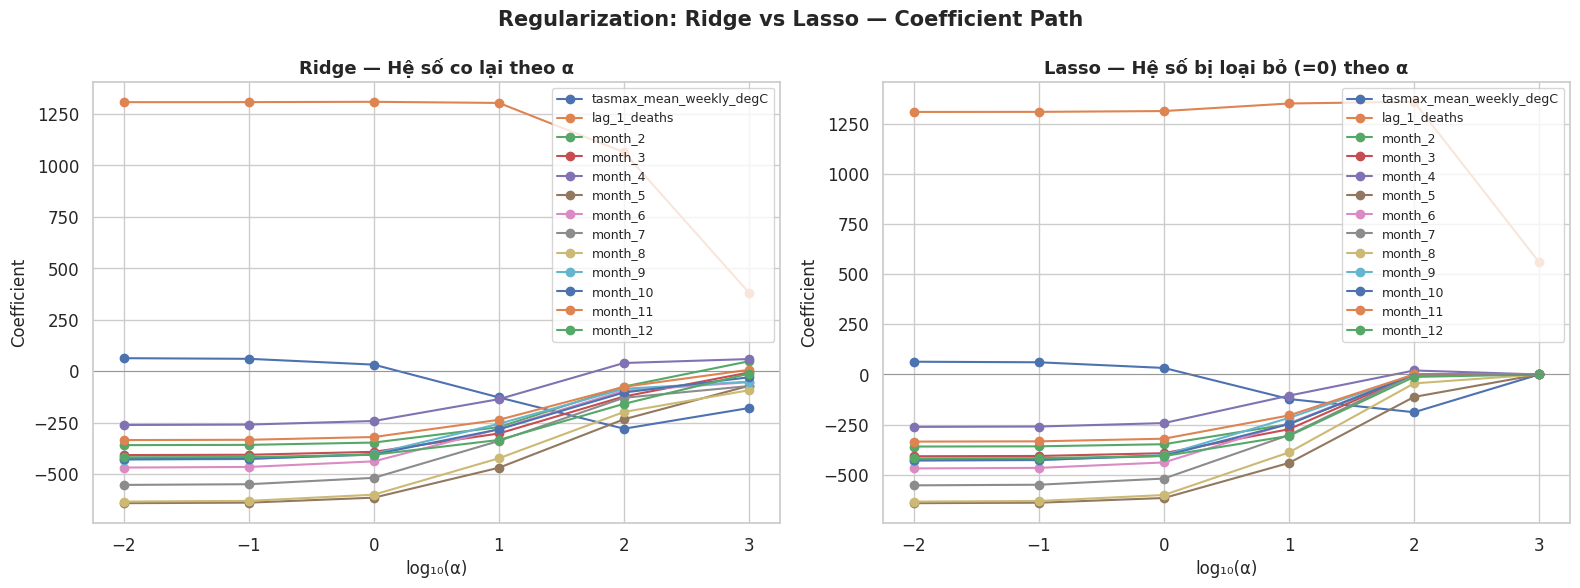


→ Best: Ridge (α=1000), R²=0.2512, RMSE=996.1


In [10]:
# Chuẩn hóa features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# So sánh Ridge & Lasso với nhiều alpha
alphas = [0.01, 0.1, 1, 10, 100, 1000]
reg_results = []

# OLS baseline
lr = LinearRegression().fit(X_train_scaled, y_train)
reg_results.append({
    'Model': 'OLS (baseline)', 'Alpha': '-',
    'R² Train': r2_score(y_train, lr.predict(X_train_scaled)),
    'R² Test': r2_score(y_test, lr.predict(X_test_scaled)),
    'RMSE Test': np.sqrt(mean_squared_error(y_test, lr.predict(X_test_scaled)))
})

for alpha in alphas:
    # Ridge
    ridge = Ridge(alpha=alpha).fit(X_train_scaled, y_train)
    reg_results.append({
        'Model': 'Ridge', 'Alpha': alpha,
        'R² Train': r2_score(y_train, ridge.predict(X_train_scaled)),
        'R² Test': r2_score(y_test, ridge.predict(X_test_scaled)),
        'RMSE Test': np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))
    })
    # Lasso
    lasso = Lasso(alpha=alpha, max_iter=10000).fit(X_train_scaled, y_train)
    reg_results.append({
        'Model': 'Lasso', 'Alpha': alpha,
        'R² Train': r2_score(y_train, lasso.predict(X_train_scaled)),
        'R² Test': r2_score(y_test, lasso.predict(X_test_scaled)),
        'RMSE Test': np.sqrt(mean_squared_error(y_test, lasso.predict(X_test_scaled)))
    })

reg_df = pd.DataFrame(reg_results).round(4)
print('SO SÁNH OLS vs RIDGE vs LASSO:')
print('=' * 70)
print(reg_df.to_string(index=False))

# Biểu đồ hệ số theo alpha
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ridge_coefs = []
lasso_coefs = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train_scaled, y_train)
    lasso = Lasso(alpha=alpha, max_iter=10000).fit(X_train_scaled, y_train)
    ridge_coefs.append(ridge.coef_)
    lasso_coefs.append(lasso.coef_)

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

for i, col in enumerate(feature_cols):
    axes[0].plot(np.log10(alphas), ridge_coefs[:, i], marker='o', label=col)
    axes[1].plot(np.log10(alphas), lasso_coefs[:, i], marker='o', label=col)

axes[0].set_xlabel('log₁₀(α)', fontsize=12)
axes[0].set_ylabel('Coefficient', fontsize=12)
axes[0].set_title('Ridge — Hệ số co lại theo α', fontweight='bold', fontsize=13)
axes[0].legend(fontsize=9)
axes[0].axhline(0, color='gray', linewidth=0.5)

axes[1].set_xlabel('log₁₀(α)', fontsize=12)
axes[1].set_ylabel('Coefficient', fontsize=12)
axes[1].set_title('Lasso — Hệ số bị loại bỏ (=0) theo α', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=9)
axes[1].axhline(0, color='gray', linewidth=0.5)

plt.suptitle('Regularization: Ridge vs Lasso — Coefficient Path', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Best model
best_reg = reg_df.loc[reg_df['R² Test'].idxmax()]
print(f'\n→ Best: {best_reg["Model"]} (α={best_reg["Alpha"]}), R²={best_reg["R² Test"]:.4f}, RMSE={best_reg["RMSE Test"]:.1f}')

## 6.11 Mô hình tổng hợp cuối cùng — So sánh tất cả

Ridge alpha selected on training folds: 100


Lasso alpha selected on training folds: 100
BẢNG TỔNG HỢP — SO SÁNH TẤT CẢ MÔ HÌNH:
               Mô hình  R² Test  RMSE Test  MAE Test
         1. OLS Linear   0.1695  1049.0247  668.4018
 2. Polynomial (deg=2)   0.3243   946.2378  650.0166
3. Ridge Poly2 (α=100)   0.3201   949.1551  675.3236
4. Lasso Poly2 (α=100)   0.2836   974.3240  651.3893


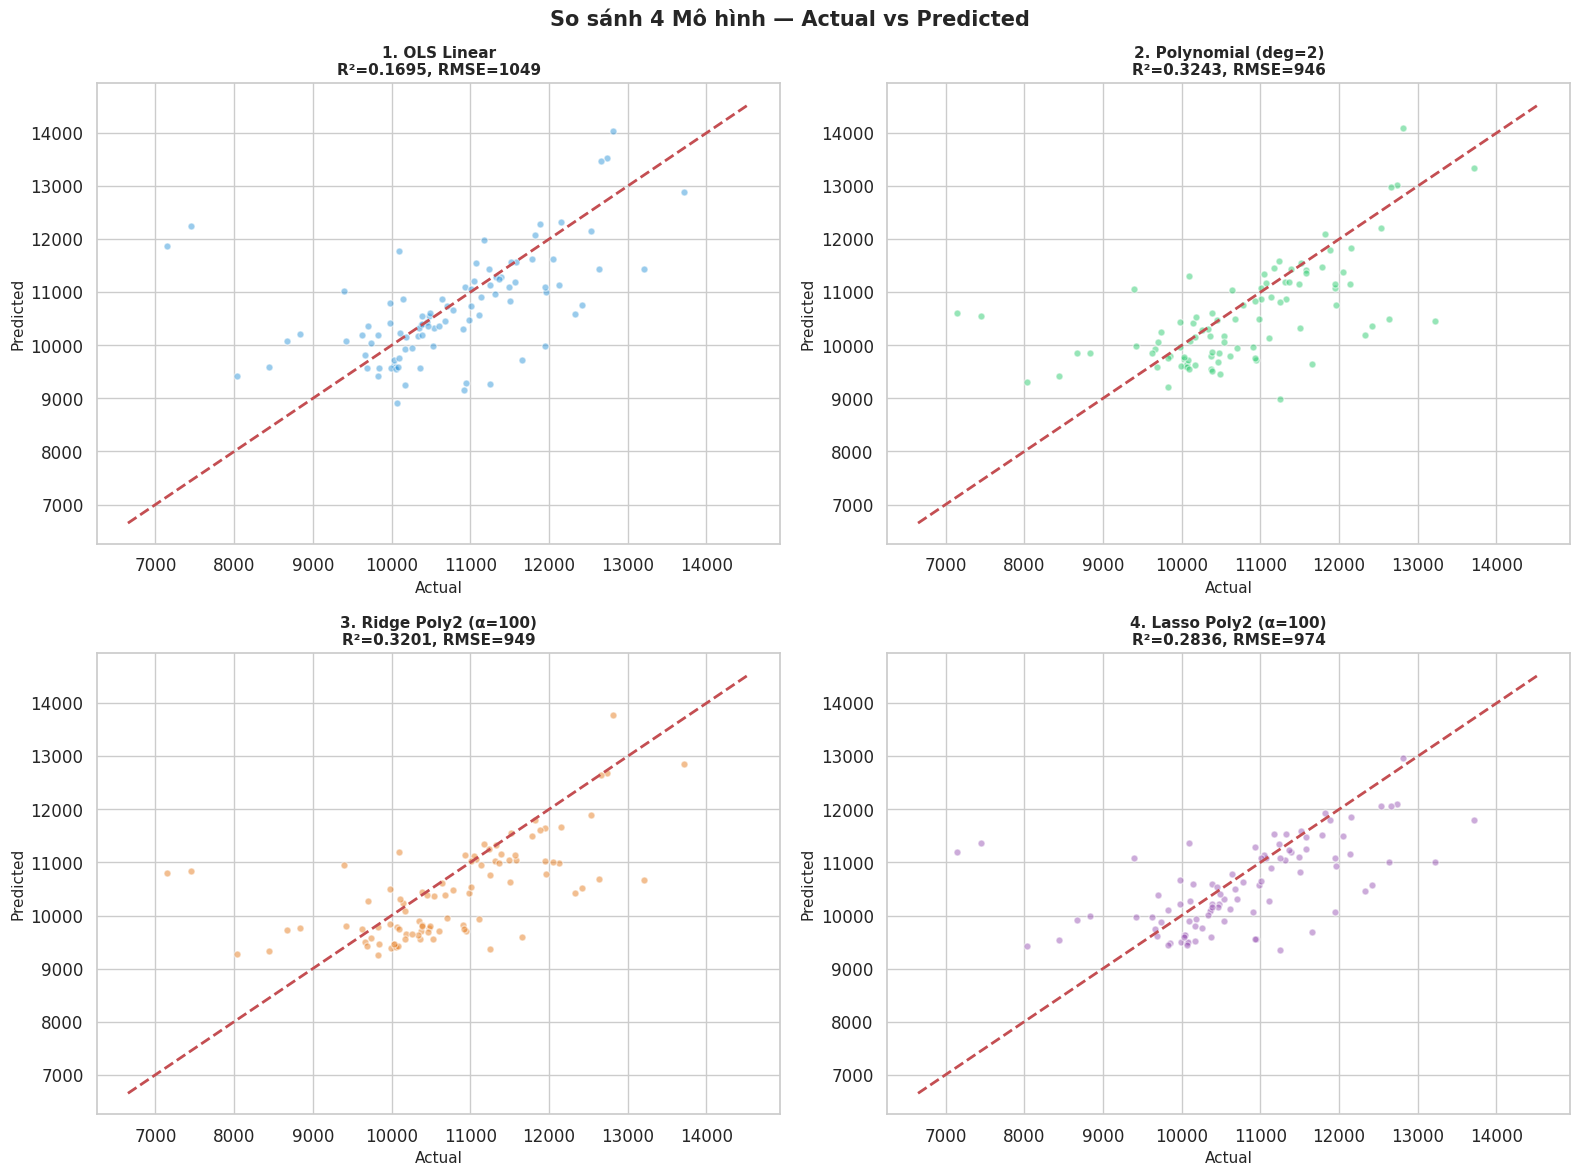


 MÔ HÌNH TỐT NHẤT: 2. Polynomial (deg=2)
   R² = 0.3243, RMSE = 946.2, MAE = 650.0


In [11]:
# Tổng hợp tất cả mô hình
final_models = []

# 1. OLS
lr_final = LinearRegression().fit(X_train, y_train)
y_pred_ols = lr_final.predict(X_test)
final_models.append({
    'Mô hình': '1. OLS Linear',
    'R² Test': r2_score(y_test, y_pred_ols),
    'RMSE Test': np.sqrt(mean_squared_error(y_test, y_pred_ols)),
    'MAE Test': mean_absolute_error(y_test, y_pred_ols)
})

# 2. Polynomial degree 2
pipe2 = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('reg', LinearRegression())
])
pipe2.fit(X_train, y_train)
y_pred_poly2 = pipe2.predict(X_test)
final_models.append({
    'Mô hình': '2. Polynomial (deg=2)',
    'R² Test': r2_score(y_test, y_pred_poly2),
    'RMSE Test': np.sqrt(mean_squared_error(y_test, y_pred_poly2)),
    'MAE Test': mean_absolute_error(y_test, y_pred_poly2)
})

# 3. Ridge. Choose alpha ONLY via folds within the training block.
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
cv=TimeSeriesSplit(n_splits=5)
alpha_grid=[0.01,0.1,1,10,100,1000]
def choose_training_alpha(kind):
    rows=[]
    for a in alpha_grid:
        pipe=Pipeline([('scaler',StandardScaler()),
                       ('poly',PolynomialFeatures(degree=2,include_bias=False)),
                       ('reg',Ridge(alpha=a) if kind=='Ridge'
                        else Lasso(alpha=a,max_iter=200000))])
        losses=-cross_val_score(pipe,X_train,y_train,cv=cv,
                                scoring='neg_mean_absolute_error',n_jobs=1)
        rows.append((a,float(losses.mean())))
    return min(rows,key=lambda t:t[1])[0],rows
best_alpha_ridge,ridge_cv_scores=choose_training_alpha('Ridge')
print('Ridge alpha selected on training folds:',best_alpha_ridge)
pipe_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('reg', Ridge(alpha=float(best_alpha_ridge)))
])
pipe_ridge.fit(X_train, y_train)
y_pred_ridge = pipe_ridge.predict(X_test)
final_models.append({
    'Mô hình': f'3. Ridge Poly2 (α={best_alpha_ridge})',
    'R² Test': r2_score(y_test, y_pred_ridge),
    'RMSE Test': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
    'MAE Test': mean_absolute_error(y_test, y_pred_ridge)
})

# 4. Lasso. Same training-only time-series CV protocol.
best_alpha_lasso,lasso_cv_scores=choose_training_alpha('Lasso')
print('Lasso alpha selected on training folds:',best_alpha_lasso)
pipe_lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('reg', Lasso(alpha=float(best_alpha_lasso), max_iter=10000))
])
pipe_lasso.fit(X_train, y_train)
y_pred_lasso = pipe_lasso.predict(X_test)
final_models.append({
    'Mô hình': f'4. Lasso Poly2 (α={best_alpha_lasso})',
    'R² Test': r2_score(y_test, y_pred_lasso),
    'RMSE Test': np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
    'MAE Test': mean_absolute_error(y_test, y_pred_lasso)
})

final_df = pd.DataFrame(final_models).round(4)
print('BẢNG TỔNG HỢP — SO SÁNH TẤT CẢ MÔ HÌNH:')
print('=' * 65)
print(final_df.to_string(index=False))

# Biểu đồ so sánh
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
model_names = final_df['Mô hình'].tolist()
predictions = [y_pred_ols, y_pred_poly2, y_pred_ridge, y_pred_lasso]
colors_m = ['#3498db', '#2ecc71', '#e67e22', '#9b59b6']

for idx, (ax, name, pred, color) in enumerate(zip(axes.flat, model_names, predictions, colors_m)):
    ax.scatter(y_test, pred, alpha=0.5, s=25, color=color, edgecolor='white')
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    ax.set_xlabel('Actual', fontsize=11)
    ax.set_ylabel('Predicted', fontsize=11)
    ax.set_title(f'{name}\nR²={r2:.4f}, RMSE={rmse:.0f}', fontweight='bold', fontsize=11)

plt.suptitle('So sánh 4 Mô hình — Actual vs Predicted', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

winner = final_df.loc[final_df['R² Test'].idxmax()]
print(f'\n MÔ HÌNH TỐT NHẤT: {winner["Mô hình"]}')
print(f'   R² = {winner["R² Test"]:.4f}, RMSE = {winner["RMSE Test"]:.1f}, MAE = {winner["MAE Test"]:.1f}')

## 6.12 Tổng kết các mô hình có nhiệt độ và giới hạn diễn giải

Phần 6.11 so sánh các mô hình **có target-week Tmax**. Kết quả có/không nhiệt độ và ba mốc tham chiếu được đối chiếu ở phần 6.13. Kết luận phải đọc cùng p-value, sai số ngoài mẫu và các giới hạn dữ liệu.

In [12]:
print('=' * 70)
print('TỔNG KẾT — REGRESSION ANALYSIS — NOTEBOOK 6')
print('=' * 70)

temp_conclusion = ('CÓ ý nghĩa thống kê ở mức 5%' if p_temp < 0.05
                   else 'CHƯA có bằng chứng về ý nghĩa thống kê ở mức 5%')
interaction_conclusion = ('có bằng chứng khác biệt theo mùa hè' if p_interaction < 0.05
                          else 'chưa đủ bằng chứng khác biệt theo mùa hè')
print(f"1. HỆ SỐ NHIỆT ĐỘ TRONG OLS: β = {coef_temp:.2f}; p = {p_temp:.4f}.")
print(f"   Kết luận: {temp_conclusion}.")
print('   Lag-1 mortality là biến dự báo mạnh; đây là quan hệ có điều kiện trong mô hình, không phải bằng chứng nhân quả.')
print(f"2. TƯƠNG TÁC MÙA HÈ: hệ số tổng ước lượng = {summer_effect:.2f} ca/°C; p(interaction) = {p_interaction:.4f}.")
print(f"   Kết luận: {interaction_conclusion}; không diễn giải thiếu ý nghĩa thống kê thành hai hiệu ứng bằng nhau.")
print('3. SO SÁNH CÁC MÔ HÌNH CÓ NHIỆT ĐỘ Ở PHẦN 6.11:')
print(f"   Điểm ước lượng tốt nhất: {winner['Mô hình']}; R² test = {winner['R² Test']:.4f}, RMSE = {winner['RMSE Test']:.1f}, MAE = {winner['MAE Test']:.1f}.")
print('   Đây là bộ so sánh +Temp; xem phần 6.13 để so cả phiên bản không nhiệt độ và ba references.')
print('4. ĐỐI CHIẾU BÀI BÁO — TABLE 3 VÀ TABLE 5:')
print('   Polynomial 2 và Lasso 2 không nhiệt độ có MAE khoảng 643.9 trên 94 tuần kiểm tra.')
print('   Last value: 738.8; seasonal naive: 703.4. MAE thấp hơn là kết quả point estimate.')
print('   Cả 12 p-value Diebold–Mariano sau Holm đều bằng 1.000: chưa xác nhận ưu thế dự báo; không chứng minh các mô hình tương đương.')
print('   Thêm nhiệt độ thay đổi pooled MAE ít và có lợi/hại khác nhau giữa các pha nhiệt độ.')
print('5. GIỚI HẠN: residuals không chuẩn và có phương sai thay đổi; target-week Tmax là dữ liệu quan sát hồi cứu.')
print('   Một holdout đã được dùng để chọn alpha; cần rolling validation độc lập trước khi tổng quát hóa.')
print('6. PHẠM VI SỬ DỤNG: phân tích mô tả và forecasting audit ở mức học phần.')
print('   Chưa đủ cơ sở triển khai cảnh báo tử vong hoặc đưa ra quyết định phân bổ nguồn lực y tế.')
print('   Hướng phát triển: dữ liệu ngày/theo vùng, biến nhiễu, dự báo thời tiết thực và khoảng dự báo.')
print('=' * 70)


TỔNG KẾT — REGRESSION ANALYSIS — NOTEBOOK 6
1. HỆ SỐ NHIỆT ĐỘ TRONG OLS: β = 12.21; p = 0.6688.
   Kết luận: CHƯA có bằng chứng về ý nghĩa thống kê ở mức 5%.
   Lag-1 mortality là biến dự báo mạnh; đây là quan hệ có điều kiện trong mô hình, không phải bằng chứng nhân quả.
2. TƯƠNG TÁC MÙA HÈ: hệ số tổng ước lượng = 65.24 ca/°C; p(interaction) = 0.2774.
   Kết luận: chưa đủ bằng chứng khác biệt theo mùa hè; không diễn giải thiếu ý nghĩa thống kê thành hai hiệu ứng bằng nhau.
3. SO SÁNH CÁC MÔ HÌNH CÓ NHIỆT ĐỘ Ở PHẦN 6.11:
   Điểm ước lượng tốt nhất: 2. Polynomial (deg=2); R² test = 0.3243, RMSE = 946.2, MAE = 650.0.
   Đây là bộ so sánh +Temp; xem phần 6.13 để so cả phiên bản không nhiệt độ và ba references.
4. ĐỐI CHIẾU BÀI BÁO — TABLE 3 VÀ TABLE 5:
   Polynomial 2 và Lasso 2 không nhiệt độ có MAE khoảng 643.9 trên 94 tuần kiểm tra.
   Last value: 738.8; seasonal naive: 703.4. MAE thấp hơn là kết quả point estimate.
   Cả 12 p-value Diebold–Mariano sau Holm đều bằng 1.000: chưa xác nhậ

---
*Trước: [5. Data Visualization](./5.%20Data%20Visualization.ipynb)* | *Hoàn thành dự án!*

## 6.13 Đối chiếu với bài báo — tái dựng đúng thiết lập mô hình của bài báo

Phần này không thay thế các mô hình gốc phía trên. Nó tái dựng **đúng cấu hình được dùng trong bài báo** để Hình 6 và Hình 7 có thể chạy lại từ dữ liệu:

- đầu vào cơ bản: `lag_1_deaths` + 11 biến giả tháng;
- phiên bản `+ Temp`: thêm `tasmax_mean_weekly_degC` của tuần mục tiêu;
- 374 tuần huấn luyện và 94 tuần kiểm tra theo thứ tự thời gian;
- mô hình chính: OLS, hồi quy đa thức bậc 2, Ridge bậc 2 (`alpha=1000`), Lasso bậc 2 (`alpha=0.01`);
- đa thức bậc 3 chỉ là kiểm tra độ phức tạp.


In [13]:
from pathlib import Path

def locate_paper_support(relative_path):
    # Accept a self-contained project folder OR the original paper_support/data layout.
    relative_path = Path(relative_path)
    candidates = []
    for root in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        candidates.extend([
            root / relative_path.name,
            root / relative_path,
            root / 'paper_support' / relative_path,
            root / 'Datasets' / 'Observed' / relative_path.name,
            root / 'Datasets' / 'Prepared' / relative_path.name,
            root / 'Datasets' / 'Regional_Reference' / relative_path.name,
            root / 'Datasets' / 'Documentation' / relative_path.name,
        ])
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(
        f'Missing data file: {relative_path.name}. Put all six notebooks and the five supplied datasets in the same folder. '
        f'Current directory: {Path.cwd()}'
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import patches, colors
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

CORAL = '#F28E79'
CORAL_DARK = '#D96652'
BLUE = '#72B7D2'
BLUE_DARK = '#2D74A6'
BLUE_LIGHT = '#DCEEF7'
YELLOW = '#F7E7A9'
GREY = '#777777'
LIGHT_GREY = '#E6E6E6'
DARK = '#333333'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.labelsize': 8, 'axes.titlesize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.linewidth': 0.7,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.03,
})

import math
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

paper_clean = pd.read_csv(locate_paper_support('data/uk_weather_health_weekly_CLEANED.csv'),
                          parse_dates=['week_start_sat','week_start_mon','week_end']).sort_values('week_start_mon').reset_index(drop=True)
df_paper = paper_clean.copy()
df_paper['lag_1_deaths'] = df_paper['deaths_total'].shift(1)
df_paper['lag_2_deaths'] = df_paper['deaths_total'].shift(2)
df_paper['seasonal_52'] = df_paper['deaths_total'].shift(52)
months = pd.get_dummies(df_paper['week_start_mon'].dt.month, prefix='month', drop_first=True, dtype=float)
df_paper = pd.concat([df_paper, months], axis=1)
month_cols_paper = list(months.columns)
model_paper = df_paper.dropna(subset=['lag_1_deaths']).reset_index(drop=True)
n_test_paper = int(math.ceil(0.20 * len(model_paper)))
train_paper = model_paper.iloc[:-n_test_paper].copy(); test_paper = model_paper.iloc[-n_test_paper:].copy()
q1 = test_paper['tasmax_mean_weekly_degC'].quantile(0.25); q3 = test_paper['tasmax_mean_weekly_degC'].quantile(0.75)
test_paper['temp_phase'] = np.where(test_paper['tasmax_mean_weekly_degC']<=q1,'Cold',np.where(test_paper['tasmax_mean_weekly_degC']>=q3,'Warm','Mild'))
base_cols_paper = ['lag_1_deaths'] + month_cols_paper
temp_cols_paper = base_cols_paper + ['tasmax_mean_weekly_degC']
y_paper = test_paper['deaths_total'].to_numpy()

def paper_factory(name):
    if name=='OLS': return Pipeline([('scale',StandardScaler()),('reg',LinearRegression())])
    if name=='Polynomial 2': return Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('reg',LinearRegression())])
    if name=='Ridge 2': return Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('reg',Ridge(alpha=1000))])
    if name=='Lasso 2': return Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('reg',Lasso(alpha=0.01,max_iter=1_000_000))])
    if name=='Polynomial 3': return Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(degree=3,include_bias=False)),('reg',LinearRegression())])

pred_paper={}; metric_rows=[]
def add_metric(name,pred):
    pred=np.asarray(pred); pred_paper[name]=pred
    baseline=mean_absolute_error(y_paper,test_paper['lag_1_deaths'].to_numpy())
    cold=test_paper['temp_phase'].eq('Cold').to_numpy(); warm=test_paper['temp_phase'].eq('Warm').to_numpy()
    metric_rows.append([name,r2_score(y_paper,pred),mean_squared_error(y_paper,pred)**0.5,mean_absolute_error(y_paper,pred),mean_absolute_error(y_paper,pred)/baseline,mean_absolute_error(y_paper[cold],pred[cold]),mean_absolute_error(y_paper[warm],pred[warm])])
add_metric('Last value',test_paper['lag_1_deaths'].to_numpy())
add_metric('Seasonal naive',test_paper['seasonal_52'].to_numpy())
add_metric('Damped trend',test_paper['lag_1_deaths'].to_numpy()+0.5*(test_paper['lag_1_deaths'].to_numpy()-test_paper['lag_2_deaths'].to_numpy()))
for name in ['OLS','Polynomial 2','Ridge 2','Lasso 2','Polynomial 3']:
    for suffix,cols in [('',base_cols_paper),(' + Temp',temp_cols_paper)]:
        m=paper_factory(name); m.fit(train_paper[cols],train_paper['deaths_total']); add_metric(name+suffix,m.predict(test_paper[cols]))
paper_metrics=pd.DataFrame(metric_rows,columns=['model','r2','rmse','mae','relative_mae','cold_mae','warm_mae'])
phase_rows=[]
for name in ['OLS','Polynomial 2','Ridge 2','Lasso 2']:
    for phase in ['Cold','Mild','Warm']:
        mask=test_paper['temp_phase'].eq(phase).to_numpy(); mae_no=mean_absolute_error(y_paper[mask],pred_paper[name][mask]); mae_temp=mean_absolute_error(y_paper[mask],pred_paper[name+' + Temp'][mask])
        phase_rows.append([name,phase,100*(mae_temp-mae_no)/mae_no,mae_no,mae_temp,int(mask.sum())])
paper_phases=pd.DataFrame(phase_rows,columns=['model','phase','mae_change_pct','mae_without','mae_with','weeks'])

print(f'Huấn luyện/Kiểm tra: {len(train_paper)} / {len(test_paper)} tuần')
print(f'Pha nhiệt độ trong tập kiểm tra: Lạnh={sum(test_paper.temp_phase=="Cold")}, Vừa={sum(test_paper.temp_phase=="Mild")}, Ấm={sum(test_paper.temp_phase=="Warm")}')

observed_dates=set(pd.read_csv('uk_weather_health_weekly_2016_2024_TOTAL_FINAL.csv')['week_start_sat'])
assert len(model_paper)==468 and len(train_paper)==374 and len(test_paper)==94
assert set(test_paper['week_start_sat'].dt.strftime('%Y-%m-%d')).issubset(observed_dates)
assert abs(float(paper_metrics.loc[paper_metrics.model.eq('Polynomial 2'),'mae'].iloc[0])-643.94)<0.1
print('PASS: 94 test outcomes all observed; Polynomial 2 MAE ~643.94.')


Huấn luyện/Kiểm tra: 374 / 94 tuần
Pha nhiệt độ trong tập kiểm tra: Lạnh=24, Vừa=46, Ấm=24
PASS: 94 test outcomes all observed; Polynomial 2 MAE ~643.94.


### Hình 6 — So sánh MAE tương đối so với mốc giá trị tuần trước

Trục dọc là `MAE của mô hình / MAE của mốc giá trị tuần trước`. Vì vậy **nhỏ hơn 1 là tốt hơn mốc giá trị tuần trước**. Mỗi mô hình hồi quy được đặt cạnh phiên bản có thêm nhiệt độ.


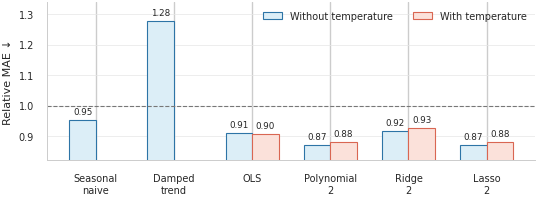

In [14]:
baseline=float(paper_metrics.loc[paper_metrics['model'].eq('Last value'),'mae'].iloc[0])
categories=['Seasonal\nnaive','Damped\ntrend','OLS','Polynomial\n2','Ridge\n2','Lasso\n2']
no_names=['Seasonal naive','Damped trend','OLS','Polynomial 2','Ridge 2','Lasso 2']
with_names=[None,None,'OLS + Temp','Polynomial 2 + Temp','Ridge 2 + Temp','Lasso 2 + Temp']
no_temp=[float(paper_metrics.loc[paper_metrics['model'].eq(n),'mae'].iloc[0]/baseline) for n in no_names]
with_temp=[np.nan if n is None else float(paper_metrics.loc[paper_metrics['model'].eq(n),'mae'].iloc[0]/baseline) for n in with_names]
x=np.arange(len(categories)); width=0.34
fig,ax=plt.subplots(figsize=(6.3,2.05)); bars1=ax.bar(x-width/2,no_temp,width,color=BLUE_LIGHT,edgecolor=BLUE_DARK,linewidth=0.8,label='Without temperature')
valid=np.array([not np.isnan(v) for v in with_temp]); bars2=ax.bar(x[valid]+width/2,np.array(with_temp)[valid],width,color='#FBE1DA',edgecolor=CORAL_DARK,linewidth=0.8,label='With temperature')
ax.axhline(1.0,color=GREY,linestyle='--',linewidth=0.8); ax.set_ylabel('Relative MAE ↓'); ax.set_xticks(x,categories); ax.set_ylim(0.82,1.34); ax.grid(axis='y',color=LIGHT_GREY,linewidth=0.5); ax.spines[['top','right']].set_visible(False); ax.legend(loc='upper right',frameon=False,ncol=2)
for bar in bars1: ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.012,f'{bar.get_height():.2f}',ha='center',va='bottom',fontsize=6.3)
for bar in bars2: ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+0.012,f'{bar.get_height():.2f}',ha='center',va='bottom',fontsize=6.3)
plt.show()


**Đối chiếu với bài báo:** Polynomial 2 và Lasso 2 thấp nhất, khoảng **0,87** khi không thêm nhiệt độ và khoảng **0,88** khi thêm nhiệt độ. OLS cải thiện nhẹ khi thêm nhiệt độ; Ridge lại xấu hơn nhẹ. Kết luận chính là **nhiệt độ chỉ làm thay đổi MAE tổng thể rất nhỏ và không đồng nhất giữa các mô hình**.


### Hình 7 — Nhiệt độ giúp hay làm xấu mô hình ở từng pha?

Tập kiểm tra được chia theo tứ phân vị nhiệt độ thành **24 tuần lạnh, 46 tuần vừa và 24 tuần ấm**. Giá trị trên trục x là phần trăm thay đổi MAE khi thêm nhiệt độ:

- **âm** → thêm nhiệt độ làm MAE giảm, tức tốt hơn;
- **dương** → thêm nhiệt độ làm MAE tăng, tức xấu hơn.


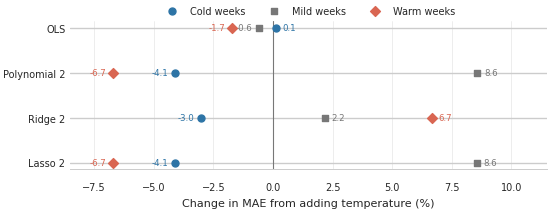

In [15]:
model_order=['OLS','Polynomial 2','Ridge 2','Lasso 2']; phase_order=['Cold','Mild','Warm']
phase_colors={'Cold':BLUE_DARK,'Mild':GREY,'Warm':CORAL_DARK}; markers={'Cold':'o','Mild':'s','Warm':'D'}; y=np.arange(len(model_order))[::-1]
fig,ax=plt.subplots(figsize=(6.15,1.92))
for phase in phase_order:
    values=[float(paper_phases.loc[(paper_phases['model'].eq(model))&(paper_phases['phase'].eq(phase)),'mae_change_pct'].iloc[0]) for model in model_order]
    ax.scatter(values,y,s=25,color=phase_colors[phase],marker=markers[phase],label=f'{phase} weeks',zorder=3)
    for xv,yv in zip(values,y): ax.text(xv+(0.28 if xv>=0 else -0.28),yv,f'{xv:.1f}',ha='left' if xv>=0 else 'right',va='center',fontsize=6.2,color=phase_colors[phase])
ax.axvline(0,color=GREY,linewidth=0.8); ax.set_yticks(y,model_order); ax.set_xlabel('Change in MAE from adding temperature (%)'); ax.set_xlim(-8.5,11.5); ax.grid(axis='x',color=LIGHT_GREY,linewidth=0.5); ax.spines[['top','right','left']].set_visible(False); ax.tick_params(axis='y',length=0); ax.legend(loc='lower center',bbox_to_anchor=(0.5,1.01),frameon=False,ncol=3,borderaxespad=0.0)
plt.show()


**Đối chiếu với bài báo:** Polynomial 2 và Lasso 2 cải thiện ở tuần lạnh (**≈ −4,1%**) và tuần ấm (**≈ −6,7%**) nhưng xấu đi ở tuần vừa (**≈ +8,6%**). Ridge cải thiện ở lạnh nhưng xấu ở vừa và ấm. Vì hai đuôi nhiệt độ chỉ có 24 tuần mỗi nhóm, bài báo không xem đây là bằng chứng ổn định rằng nhiệt độ hữu ích nhất ở cực trị.


### Kết luận cuối cùng

Polynomial 2 và Lasso 2 **không thêm nhiệt độ** cho MAE thấp nhất, khoảng **643,9 ca/tuần** trên 94 tuần kiểm tra. Thêm nhiệt độ có đóng góp nhỏ và không ổn định. Table 5 của báo cáo không xác nhận ưu thế dự báo sau Holm. Dữ liệu chỉ hỗ trợ mô tả và forecasting audit; chưa đủ cơ sở đưa mô hình vào cảnh báo y tế.

**Reproducibility:** the five included files can be placed beside the notebooks; `paper_support` is no longer required. The paper-replication results use its fixed alphas and previously reused test; the training-only CV in §6.11 is evaluated separately.

## Paper-aligned result table (computed, not typed)

The table below reproduces the fixed-parameter benchmark used in the report and supports comparison of the four principal regression families with the degree-three complexity check. This is **retrospective** and does not imply superiority after multiple-testing correction.

In [16]:
from IPython.display import display
cols_to_show=['model','mae','rmse','r2','relative_mae']
display(paper_metrics[cols_to_show].round(3).sort_values('mae').reset_index(drop=True))
print('Five regression configurations: OLS, Polynomial 2, Ridge 2, Lasso 2, Polynomial 3.')
print('Four primary families plus one degree-three complexity check.')
print('Reported p-values adjusted by Holm did not establish clear superiority.')


,model,mae,rmse,r2,relative_mae
0,Lasso 2,643.935,939.024,0.335,0.872
1,Polynomial 2,643.940,939.029,0.335,0.872
2,Lasso 2 + Temp,649.908,946.141,0.324,0.880
3,Polynomial 2 + Temp,650.017,946.238,0.324,0.880
4,Polynomial 3,657.706,998.271,0.248,0.890
5,OLS + Temp,668.402,1049.025,0.170,0.905
6,OLS,672.036,1051.216,0.166,0.910
7,Ridge 2,677.331,965.793,0.296,0.917
8,Ridge 2 + Temp,684.966,963.147,0.300,0.927
9,Seasonal naive,703.426,1001.014,0.244,0.952


Five regression configurations: OLS, Polynomial 2, Ridge 2, Lasso 2, Polynomial 3.
Four primary families plus one degree-three complexity check.
Reported p-values adjusted by Holm did not establish clear superiority.


## Final checks / Verification

The following assertions are executable checks, not manually entered model results.

In [17]:
assert len(test_paper)==94 and len(train_paper)==374
print('PASS: 374 training and 94 observed test weeks.')

PASS: 374 training and 94 observed test weeks.
